# 03_3. M2 — neural network (MLP) / M2 — нейросеть (MLP)

**EN.** M2 is a plain fully connected neural network on the same 18 features, with the same exposure weight ω × 1/r and the same tuning budget as CatBoost (40 Optuna trials, log-loss on half A; the task is Y1). Its role: an honest comparison of boosting and a neural network on one problem; CatBoost is expected to be stronger on tabular data.

How the network sees the data:
- **numeric features** go through a quantile transform fitted on train (each value is replaced by the matching quantile of a normal distribution; heavy tails of UPB changes stop dominating); a missing value becomes 0 plus a 0/1 "missing" indicator;
- **categorical features** (seller, loan purpose, property type, occupancy, first-time buyer) get learned **embeddings** — short vectors the network learns for every category;
- 2–4 hidden layers (Linear → ReLU → Dropout); output = logit of PD;
- training: AdamW on weighted cross-entropy (BCE); after every pass over train (**epoch**) the log-loss on half A is computed, and training stops when it has not improved for 3 epochs (**early stopping**); computed on the Apple GPU (MPS).

The best configuration is trained with **5 seeds** (different random initialisation and batch order): the spread shows how stable the network is; the M2 prediction is the mean logit of the 5 seeds.

**RU.** M2 — обычная полносвязная нейросеть на тех же 18 признаках, с тем же весом ω × 1/r и тем же бюджетом подбора, что у CatBoost (40 попыток Optuna, log-loss на половине A; задача — Y1). Её роль — честное сравнение бустинга и нейросети на одной задаче; на табличных данных ожидается, что CatBoost сильнее.

Как сеть видит данные:
- **числовые признаки** проходят квантильное преобразование, обученное на train (значение заменяется соответствующим квантилем нормального распределения, и тяжёлые хвосты изменений ОД перестают доминировать); пропуск становится 0 плюс индикатор «пропуск» 0/1;
- **категориальные признаки** (продавец, цель кредита, тип объекта, тип проживания, первая покупка) получают обучаемые **эмбеддинги** — короткие векторы, которые сеть выучивает для каждой категории;
- 2–4 скрытых слоя (Linear → ReLU → Dropout); выход — логит PD;
- обучение: AdamW на взвешенной кросс-энтропии (BCE); после каждого прохода по train (**эпохи**) считается log-loss на половине A, и обучение останавливается, если он не улучшался 3 эпохи (**ранняя остановка**); расчёт на графическом процессоре Apple (MPS).

Лучшая конфигурация обучается с **5 seed** (разная случайная инициализация и порядок батчей): разброс показывает устойчивость сети; прогноз M2 — средний логит 5 seed.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.evaluation.metrics import all_metrics, auc, sigmoid
from xai_ews.models import registry
from xai_ews.models.calibration import Platt
from xai_ews.models.data import load_eval
from xai_ews.paths import PREDICTIONS_DIR, MODELING_DIR

STUDIES = {"y1": "mlp_y1_main"}

### 1. Tuning results / Результаты подбора

**EN.** Best trial, its configuration, epochs until early stopping, log-loss and AUC on half A, and the CatBoost result of the same study setting for reference.

**RU.** Лучшая попытка, её конфигурация, число эпох до ранней остановки, log-loss и AUC на половине A и для сравнения результат CatBoost при тех же условиях подбора.

In [2]:
rows, hist = [], {}
for task, s in STUDIES.items():
    df = registry.trials_frame(s)
    df = df[df["state"] == "COMPLETE"].sort_values("number")
    df.to_csv(MODELING_DIR / f"tuning_{s}.csv", index=False)
    hist[task] = df
    b = df.loc[df["value"].idxmin()]
    try:                                  # CatBoost studies come from Colab (GPU)
        cbs = registry.study(f"catboost_{task}_main")
        cb_ll, cb_auc = cbs.best_value, cbs.best_trial.user_attrs["auc_A"]
    except KeyError:
        cb_ll = cb_auc = np.nan
    rows.append({"task": task, "trials": len(df), "best_trial": int(b["number"]), "log_loss_A": b["value"],
                 "auc_A": b["user_attrs_auc_A"], "epochs": int(b["user_attrs_epochs"]),
                 **{k.removeprefix("params_"): b[k] for k in df.columns if k.startswith("params_")},
                 "catboost_log_loss_A": cb_ll, "catboost_auc_A": cb_auc, "hours": df["duration"].sum().total_seconds() / 3600,
                 "auc_A_spread_top5": df.nsmallest(5, "value")["user_attrs_auc_A"].std()})
mlp_tuning = pd.DataFrame(rows).set_index("task")
mlp_tuning.to_csv(MODELING_DIR / "tuning_mlp_summary.csv")
mlp_tuning.T

task,y1
trials,40.0000
best_trial,17.0000
log_loss_A,0.0123
auc_A,0.8583
epochs,14.0000
batch_size,"4,096.0000"
dropout,0.3544
emb_dim,4.0000
lr,0.0003
n_layers,4.0000


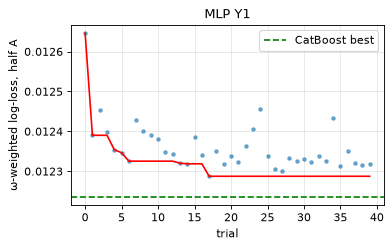

In [3]:
fig, axes = plt.subplots(1, len(STUDIES), figsize=(5 * len(STUDIES), 3.2), squeeze=False)
axes = axes[0]
for ax, (task, df) in zip(axes, hist.items()):
    ax.plot(df["number"], df["value"], "o", ms=3, alpha=0.6); ax.plot(df["number"], df["value"].cummin(), "r-")
    ax.axhline(mlp_tuning.loc[task, "catboost_log_loss_A"], c="g", ls="--", label="CatBoost best")
    ax.set_title(f"MLP {task.upper()}"); ax.set_xlabel("trial"); ax.legend()
axes[0].set_ylabel("ω-weighted log-loss, half A")
plt.tight_layout(); plt.show()

**EN. How to read.** Best configuration: 4 layers × 256, dropout 0.35, learning rate 2.8·10⁻⁴, weight decay 3·10⁻³, batch 4,096, embeddings of size 4, best epoch 14. All five best trials chose batch 4,096 and embedding size 4 (3–4 layers, 11–25 epochs): with few categories of weak effect the network prefers small embeddings and large, smooth batches. The optimum is flat: 35 of 40 trials are within 1 % of the best log-loss. On half A the best MLP trial (log-loss 0.012288, AUC 0.858) is slightly worse than the best CatBoost trial (0.012236, AUC 0.863). Tuning took 1.7 hours on the Apple GPU.

**RU. Как читать.** Лучшая конфигурация: 4 слоя × 256, dropout 0,35, скорость обучения 2,8·10⁻⁴, weight decay 3·10⁻³, батч 4 096, эмбеддинги размера 4, лучшая эпоха — 14. Все пять лучших попыток выбрали батч 4 096 и эмбеддинг размера 4 (3–4 слоя, 11–25 эпох): при немногих категориях со слабым эффектом сеть предпочитает маленькие эмбеддинги и крупные, «гладкие» батчи. Оптимум плоский: 35 из 40 попыток в пределах 1 % от лучшего log-loss. На половине A лучшая попытка MLP (log-loss 0,012288, AUC 0,858) немного хуже лучшей попытки CatBoost (0,012236, AUC 0,863). Подбор занял 1,7 часа на графическом процессоре Apple.

### 2. Five seeds / Пять seed

**EN.** The best configuration retrained with 5 seeds (`scripts/fit_models.py`). For each seed: AUC and log-loss on half A after Platt calibration on half B; then the mean ± std over seeds and the metrics of the seed average (the M2 prediction).

**RU.** Лучшая конфигурация переобучена с 5 seed (`scripts/fit_models.py`). Для каждого seed: AUC и log-loss на половине A после калибровки Платта на половине B; затем среднее ± std по seed и метрики среднего по seed (прогноз M2).

In [4]:
seed_rows, summary = [], []
for task in STUDIES:
    name = f"m2_{task}"
    m = registry.meta(name)
    va = load_eval("validation", task, m["features"], m["categorical"])
    mean_logit, per_seed = registry.predict_mlp(name, va, per_seed=True)
    p = va.select("loan_identifier", "m", task, "half", "upb", "omega").with_columns(pl.Series("logit", mean_logit))
    p.write_parquet(PREDICTIONS_DIR / f"{name}_validation.parquet")
    a, b = (va["half"] == "A").to_numpy(), (va["half"] == "B").to_numpy()
    y = va[task].to_numpy()
    for s, z in enumerate(per_seed):
        cal = Platt().fit(z[b], y[b])
        seed_rows.append({"task": task, "seed": s, "epochs": m["epochs"][s], **all_metrics(y[a], cal.predict(z[a]))})
    cal = Platt().fit(mean_logit[b], y[b])
    summary.append({"task": task, "seeds": "mean of 5", **all_metrics(y[a], cal.predict(mean_logit[a]))})
    del va; gc.collect()
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(MODELING_DIR / "m2_seeds_validation.csv", index=False)
cols = ["auc", "ks", "pr_auc", "brier", "log_loss", "ece", "cal_slope", "cal_intercept"]
agg = seeds.groupby("task")[cols].agg(["mean", "std"])
display(seeds.set_index(["task", "seed"])[["epochs", *cols]])
display(agg)
m2_val = pd.DataFrame(summary).set_index("task")
m2_val.to_csv(MODELING_DIR / "m2_validation_metrics.csv")
m2_val[cols]

epochs    auc     ks  pr_auc  brier  log_loss    ece  cal_slope  cal_intercept
task seed                                                                                
y1   0         13 0.8585 0.5671  0.0149 0.0020    0.0124 0.0001     1.0636        -0.0062
     1          5 0.8554 0.5596  0.0141 0.0020    0.0124 0.0002     1.0699        -0.0076
     2          5 0.8503 0.5512  0.0137 0.0020    0.0125 0.0001     1.0366        -0.0073
     3          8 0.8541 0.5534  0.0138 0.0020    0.0124 0.0001     1.0421        -0.0073
     4         13 0.8576 0.5588  0.0153 0.0020    0.0124 0.0001     1.0553        -0.0083

auc            ks        pr_auc         brier        log_loss           ece        cal_slope        cal_intercept       
       mean    std   mean    std   mean    std   mean    std     mean    std   mean    std      mean    std          mean    std
task                                                                                                                            
y1   0.8552 0.0032 0.5580 0.0062 0.0144 0.0007 0.0020 0.0000   0.0124 0.0001 0.0001 0.0000    1.0535 0.0141       -0.0073 0.0008

,auc,ks,pr_auc,brier,log_loss,ece,cal_slope,cal_intercept
task,,,,,,,,
y1,0.8579,0.5672,0.0147,0.0020,0.0124,0.0001,1.0544,-0.0073


**EN. How to read.** The seeds differ noticeably: AUC 0.855 ± 0.003 (0.850–0.859), and the epoch of early stopping varies from 5 to 13 — with about 1,000 loans with an event in half A the stopping point is noisy. Averaging the 5 seeds smooths this out: **M2 = AUC 0.858, KS 0.57, PR-AUC 0.015**, calibration after Platt slope 1.05, intercept −0.007. M1 (CatBoost) on the same half A: AUC 0.863, KS 0.57, PR-AUC 0.016, slope 1.05. So the network is **slightly weaker than CatBoost** (−0.005 AUC), as the methodology expected for tabular data, and equally well calibrated. Test (03_6) decides whether the difference is significant.

**RU. Как читать.** Seed заметно различаются: AUC 0,855 ± 0,003 (0,850–0,859), а эпоха ранней остановки — от 5 до 13: при примерно 1 000 кредитов с событием на половине A момент остановки шумный. Усреднение 5 seed это сглаживает: **M2 — AUC 0,858, KS 0,57, PR-AUC 0,015**, калибровка после Платта: наклон 1,05, сдвиг −0,007. M1 (CatBoost) на той же половине A: AUC 0,863, KS 0,57, PR-AUC 0,016, наклон 1,05. Значит, нейросеть **немного слабее CatBoost** (−0,005 AUC), как и ожидала методология для табличных данных, и так же хорошо откалибрована. Значимость различия решит test (03_6).